# **Trabajo práctico integrador**
## **Implementación de modelos de aprendizaje automático**
### *Desarrollo, implementación y monitoreo de un modelo predictivo de cancelación de reservas hoteleras.*

Estudiantes:


*   Alves Daniela
*   Feliú Cynthia F.
*   Davila Alvaro




# 1. ENTENDIMIENTO DEL PROBLEMA

## 1.1. Contexto de negocio

El presente trabajo propone el desarrollo, implementación y monitoreo de un modelo de aprendizaje automático destinado a predecir la cancelación de reservas hoteleras.

Se plantea como escenario una organización hotelera ficticia que administra dos establecimientos: un hotel urbano (*City Hotel*) y un hotel vacacional (*Resort Hotel*). Ambos reciben reservas con diferentes características, como anticipación, segmento de mercado, tipo de depósito y antecedentes del cliente.

La cancelación de reservas representa un desafío para la gestión comercial, ya que puede generar habitaciones disponibles que no siempre logran comercializarse nuevamente, afectando la ocupación y los ingresos potenciales.

## 1.2. Problema y objetivo predictivo

El problema consiste en identificar anticipadamente las reservas con mayor probabilidad de cancelación, para que el equipo de reservas pueda priorizar acciones de seguimiento.

Se desarrollará un modelo de clasificación binaria cuya variable objetivo será `is_canceled`:

- **1:** reserva cancelada.
- **0:** reserva no cancelada.

El modelo utilizará características disponibles al momento de emitir la predicción, evitando variables que revelen el resultado final de la reserva.

## 1.3. Utilidad para el negocio

Las predicciones permitirían clasificar las reservas según su riesgo de cancelación y priorizar aquellas que requieren seguimiento.

Se consideran dos tipos de errores:

- **Falso positivo:** identificar como riesgosa una reserva que finalmente no se cancela. Genera esfuerzos de seguimiento innecesarios.
- **Falso negativo:** no identificar una reserva que posteriormente se cancela. Reduce las posibilidades de anticipar acciones comerciales.

Como objetivos iniciales se propone identificar al menos el 60% de las cancelaciones reales (*recall*) y lograr que al menos el 50% de las alertas emitidas sean correctas (*precision*).

Estos umbrales serán contrastados con los resultados de los modelos y con una línea base.

## 1.4. Fuente de datos y arquitectura propuesta

Se utilizará el conjunto de datos público *Hotel Booking Demand*, que contiene información histórica de reservas de dos tipos de establecimientos hoteleros.

Para el escenario propuesto, los datos serían exportados desde el sistema de gestión de reservas, almacenados en archivos estructurados y procesados mediante Python.

El flujo contempla las siguientes etapas:

**Fuente de datos → Almacenamiento → Preparación y transformación → Modelo predictivo → Aplicación para el equipo de reservas → Registro y monitoreo.**

Se propone publicar el modelo mediante una aplicación desarrollada en Streamlit, que permita introducir las características de una reserva y obtener su predicción de cancelación.

Las predicciones serán registradas en una bitácora para facilitar el seguimiento del funcionamiento del modelo.



# 2. PREPARACION DE LOS DATOS

In [2]:
# Importación de librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

In [33]:
# Lectura del dataset desde la web
url = "https://raw.githubusercontent.com/Sid-darthvader/DoWhy-The-Causal-Story-Behind-Hotel-Booking-Cancellations/master/hotel_bookings.csv"
df = pd.read_csv(url)

# Visualización de los primeros registros
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [34]:
#Primeras observaciones
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [35]:
# Dimensiones del dataset
print("Cantidad de reservas:", df.shape[0])
print("Cantidad de variables:", df.shape[1])

Cantidad de reservas: 119390
Cantidad de variables: 32


## Evaluación inicial de calidad de datos

In [36]:

# Resumen de valores faltantes
faltantes = pd.DataFrame({
    'Tipo de dato': df.dtypes.astype(str),
    'Faltantes': df.isnull().sum(),
    'Porcentaje (%)': (
        df.isnull().mean() * 100
    ).round(2)
})

# Mostrar variables con valores faltantes
print("VARIABLES CON DATOS FALTANTES")
display(
    faltantes[faltantes['Faltantes'] > 0]
    .sort_values('Faltantes', ascending=False)
)

# Identificar registros repetidos
duplicados = df.duplicated().sum()

print("\nREGISTROS DUPLICADOS")
print("Cantidad:", duplicados)
print(
    "Porcentaje:",
    round(duplicados / len(df) * 100, 2), "%"
)

# Distribución de la variable objetivo
print("\nDISTRIBUCIÓN DE CANCELACIONES")

cancelaciones = pd.DataFrame({
    'Cantidad': df['is_canceled'].value_counts(),
    'Porcentaje (%)': (
        df['is_canceled']
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(cancelaciones)


VARIABLES CON DATOS FALTANTES


,Tipo de dato,Faltantes,Porcentaje (%)
company,float64,112593,94.31
agent,float64,16340,13.69
country,object,488,0.41
children,float64,4,0.00



REGISTROS DUPLICADOS
Cantidad: 31994
Porcentaje: 26.8 %

DISTRIBUCIÓN DE CANCELACIONES


,Cantidad,Porcentaje (%)
is_canceled,,
0,75166,62.96
1,44224,37.04


El conjunto de datos contiene 119.390 registros y 32 variables. Se identificaron valores faltantes en cuatro columnas: company (94,31%), agent (13,69%), country (0,41%) y children (4 observaciones).

La elevada proporción de valores faltantes en company limita su utilización directa como predictor, mientras que las restantes variables podrían tratarse mediante técnicas de imputación, dependiendo de su relevancia para el modelo.

Asimismo, se identificaron 31.994 registros idénticos, equivalentes al 26,80% del dataset. Dado que no se dispone de un identificador único de reserva, no es posible determinar si corresponden a duplicaciones de carga o a reservas diferentes con características coincidentes. Por este motivo, se conservarán inicialmente y se considerará su posible efecto sobre la evaluación del modelo.

Respecto de la variable objetivo, el 37,04% de las reservas fueron canceladas, mientras que el 62,96% no registró cancelación. Esta distribución muestra una clase minoritaria relevante, por lo que se prestará especial atención a la capacidad del modelo para identificar cancelaciones, evitando utilizar la exactitud global como único criterio de evaluación.

## Separación del lote de producción

In [38]:
# Reservas de julio y agosto de 2017
filtro_produccion = (
    (df['arrival_date_year'] == 2017) &
    (df['arrival_date_month'].isin(['July', 'August']))
)

# Lote reservado para simular producción
df_produccion = df.loc[filtro_produccion].copy()

# Datos disponibles para desarrollo del modelo
datos = df.loc[~filtro_produccion].copy()

print("RESERVAS PARA DESARROLLO:", len(datos))
print("RESERVAS RESERVADAS PARA PRODUCCIÓN:", len(df_produccion))

print("\nPorcentaje reservado para producción:")
print(round(len(df_produccion) / len(df) * 100, 2), "%")

print("\nVerificación del total:")
print(len(datos) + len(df_produccion))


RESERVAS PARA DESARROLLO: 109152
RESERVAS RESERVADAS PARA PRODUCCIÓN: 10238

Porcentaje reservado para producción:
8.58 %

Verificación del total:
119390


## Análisis exploratorio de variables predictoras

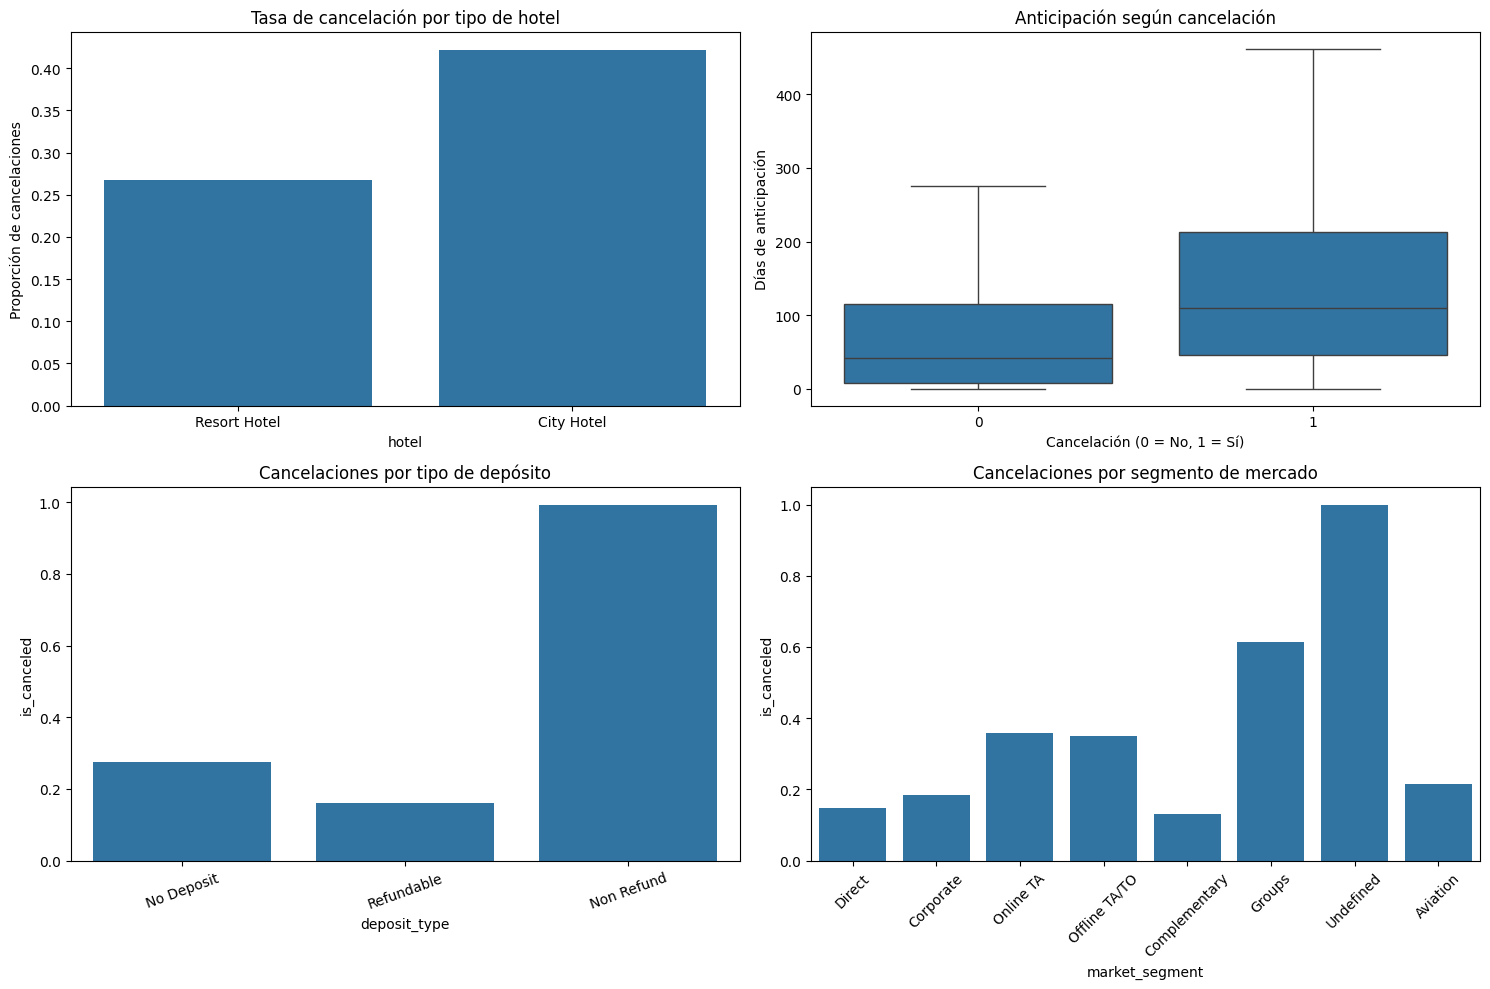


CANCELACIONES SEGÚN HOTEL


,reservas,tasa_cancelacion
hotel,,
City Hotel,72646,42.20
Resort Hotel,36506,26.76



CANCELACIONES SEGÚN DEPOSIT_TYPE


,reservas,tasa_cancelacion
deposit_type,,
No Deposit,94648,27.62
Non Refund,14354,99.36
Refundable,150,16.00



CANCELACIONES SEGÚN MARKET_SEGMENT


,reservas,tasa_cancelacion
market_segment,,
Online TA,49741,35.73
Offline TA/TO,22736,35.03
Groups,19394,61.50
Direct,11231,14.86
Corporate,5104,18.50
Complementary,712,13.06
Aviation,232,21.55
Undefined,2,100.00



ANTICIPACIÓN SEGÚN CANCELACIÓN


,count,mean,median
is_canceled,,,
0,68728,74.91,41.0
1,40424,142.95,110.0


In [40]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Cancelaciones según tipo de hotel
sns.barplot(
    data=datos, x='hotel', y='is_canceled',
    errorbar=None, ax=axes[0, 0]
)
axes[0, 0].set_title('Tasa de cancelación por tipo de hotel')
axes[0, 0].set_ylabel('Proporción de cancelaciones')

# 2. Anticipación de la reserva
sns.boxplot(
    data=datos, x='is_canceled', y='lead_time',
    showfliers=False, ax=axes[0, 1]
)
axes[0, 1].set_title('Anticipación según cancelación')
axes[0, 1].set_xlabel('Cancelación (0 = No, 1 = Sí)')
axes[0, 1].set_ylabel('Días de anticipación')

# 3. Cancelaciones según depósito
sns.barplot(
    data=datos, x='deposit_type', y='is_canceled',
    errorbar=None, ax=axes[1, 0]
)
axes[1, 0].set_title('Cancelaciones por tipo de depósito')
axes[1, 0].tick_params(axis='x', rotation=20)

# 4. Cancelaciones según segmento de mercado
sns.barplot(
    data=datos, x='market_segment', y='is_canceled',
    errorbar=None, ax=axes[1, 1]
)
axes[1, 1].set_title('Cancelaciones por segmento de mercado')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Tablas para interpretar resultados
for variable in ['hotel', 'deposit_type', 'market_segment']:
    print(f'\nCANCELACIONES SEGÚN {variable.upper()}')
    tabla = datos.groupby(variable)['is_canceled'].agg(
        reservas='count',
        tasa_cancelacion='mean'
    )
    tabla['tasa_cancelacion'] = (
        tabla['tasa_cancelacion'] * 100
    ).round(2)
    display(tabla.sort_values('reservas', ascending=False))

print('\nANTICIPACIÓN SEGÚN CANCELACIÓN')
display(
    datos.groupby('is_canceled')['lead_time']
    .agg(['count', 'mean', 'median'])
    .round(2)
)


El análisis exploratorio se realizó sobre las 109.152 reservas destinadas al desarrollo del modelo, manteniendo excluidas las 10.238 observaciones reservadas para simular producción.

Se identificaron diferencias relevantes en las tasas de cancelación según el tipo de establecimiento. El hotel urbano (City Hotel) presentó una tasa del 42,20%, frente al 26,76% registrado en el hotel vacacional (Resort Hotel), lo que representa una diferencia de 15,44 puntos porcentuales.

El tipo de depósito también mostró una asociación importante con la variable objetivo. Las reservas clasificadas como Non Refund registraron una tasa de cancelación del 99,36%, mientras que aquellas sin depósito (No Deposit) presentaron un 27,62%. Este comportamiento requiere una interpretación cautelosa y una revisión de su disponibilidad al momento de generar predicciones.

En cuanto al segmento de mercado, las reservas grupales (Groups) presentaron una tasa de cancelación del 61,50%, considerablemente superior a la de las reservas directas (Direct), que alcanzó el 14,86%.

Por último, se observó una relación entre la anticipación de la reserva y su cancelación. Las reservas canceladas presentaron una anticipación media de 142,95 días, frente a 74,91 días en las no canceladas. Las medianas fueron de 110 y 41 días, respectivamente, lo que confirma que la diferencia no depende exclusivamente de valores extremos.

Estos resultados sugieren que las características comerciales de la reserva y su anticipación contienen información potencialmente útil para la clasificación predictiva. No obstante, las asociaciones identificadas no implican relaciones causales y deberán contrastarse mediante el entrenamiento y la evaluación de los modelos.

## Pipeline de preprocesamiento

In [45]:

# PIPELINE DE PREPROCESAMIENTO

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Selección de variables predictoras
variables_numericas = [
    'lead_time',
    'previous_cancellations',
    'stays_in_week_nights',
    'stays_in_weekend_nights'
]

variables_categoricas = [
    'hotel',
    'deposit_type',
    'market_segment',
    'customer_type',
    'is_repeated_guest'
]

variables = variables_numericas + variables_categoricas

# Preparación de variables numéricas
pipeline_numerico = Pipeline([
    ('imputacion', SimpleImputer(strategy='median')),
    ('escalado', StandardScaler())
])

# Preparación de variables categóricas
pipeline_categorico = Pipeline([
    ('imputacion', SimpleImputer(strategy='most_frequent')),
    ('codificacion', OneHotEncoder(handle_unknown='ignore'))
])

# Integración de transformaciones
preprocesador = ColumnTransformer(
    transformers=[
        ('numericas', pipeline_numerico, variables_numericas),
        ('categoricas', pipeline_categorico, variables_categoricas)
    ]
)

# Definición de predictores y variable objetivo
X = datos[variables].copy()
y = datos['is_canceled'].copy()

# Lote reservado para producción
X_produccion = df_produccion[variables].copy()
y_produccion = df_produccion['is_canceled'].copy()

print("Pipeline de preprocesamiento definido correctamente.")
print("Variables numéricas:", len(variables_numericas))
print("Variables categóricas:", len(variables_categoricas))
print("Total de predictores:", len(variables))
print("Reservas para desarrollo:", len(X))
print("Reservas reservadas para producción:", len(X_produccion))

display(preprocesador)


Pipeline de preprocesamiento definido correctamente.
Variables numéricas: 4
Variables categóricas: 5
Total de predictores: 9
Reservas para desarrollo: 109152
Reservas reservadas para producción: 10238


ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputacion',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalado',
                                                  StandardScaler())]),
                                 ['lead_time', 'previous_cancellations',
                                  'stays_in_week_nights',
                                  'stays_in_weekend_nights']),
                                ('categoricas',
                                 Pipeline(steps=[('imputacion',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('codificacion',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['hotel', 'deposit_type', 'market_segment',
                                  'customer_type', 'is_repeated_guest'])])

# 3. MODELADO

## Separación de entrenamiento y prueba

In [46]:

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import numpy as np

# Identificar filas idénticas utilizando todas las columnas
# originales del conjunto de desarrollo
grupos = pd.util.hash_pandas_object(
    datos.fillna('__VALOR_FALTANTE__'),
    index=False
)

# Separación agrupada: aproximadamente 80% / 20%
separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

indices_train, indices_test = next(
    separador.split(X, y, groups=grupos)
)

X_train = X.iloc[indices_train].copy()
X_test = X.iloc[indices_test].copy()

y_train = y.iloc[indices_train].copy()
y_test = y.iloc[indices_test].copy()

# Verificar ausencia de grupos idénticos compartidos
grupos_train = set(grupos.iloc[indices_train])
grupos_test = set(grupos.iloc[indices_test])

print("Entrenamiento:", len(X_train))
print("Evaluación:", len(X_test))
print("Producción reservada:", len(X_produccion))

print("\nCancelaciones:")
print("Entrenamiento:", round(y_train.mean()*100, 2), "%")
print("Evaluación:", round(y_test.mean()*100, 2), "%")

print("\nGrupos idénticos compartidos:",
      len(grupos_train.intersection(grupos_test)))


Entrenamiento: 87466
Evaluación: 21686
Producción reservada: 10238

Cancelaciones:
Entrenamiento: 37.11 %
Evaluación: 36.71 %

Grupos idénticos compartidos: 0


## Línea base y función de evaluación

In [47]:
# Línea base y función de evaluación

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

resultados = []

def evaluar_modelo(nombre, modelo, X_eval, y_eval):
    predicciones = modelo.predict(X_eval)
    probabilidades = modelo.predict_proba(X_eval)[:, 1]

    metricas = {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_eval, predicciones),
        'Precision': precision_score(
            y_eval, predicciones, zero_division=0
        ),
        'Recall': recall_score(
            y_eval, predicciones, zero_division=0
        ),
        'F1': f1_score(
            y_eval, predicciones, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            y_eval, probabilidades
        )
    }

    resultados.append(metricas)

    print(f"\n{nombre}")
    display(pd.DataFrame([metricas]).round(4))

    print("Matriz de confusión:")
    print(confusion_matrix(y_eval, predicciones))


baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

evaluar_modelo(
    'Línea base',
    baseline,
    X_test,
    y_test
)



Línea base


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Línea base,0.6329,0.0,0.0,0.0,0.5


Matriz de confusión:
[[13724     0]
 [ 7962     0]]


##Regresión Logística

In [49]:
# Regresión Logística

from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.pipeline import Pipeline

modelo_logistico = Pipeline([
    ('preprocesamiento', clone(preprocesador)),
    ('clasificador', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

modelo_logistico.fit(X_train, y_train)

evaluar_modelo(
    'Regresión logística',
    modelo_logistico,
    X_test,
    y_test
)



Regresión logística


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Regresión logística,0.7834,0.9228,0.4475,0.6027,0.8128


Matriz de confusión:
[[13426   298]
 [ 4399  3563]]


##Random Forest

In [50]:
# Random Forest

from sklearn.ensemble import RandomForestClassifier

modelo_rf = Pipeline([
    ('preprocesamiento', clone(preprocesador)),
    ('clasificador', RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf.fit(X_train, y_train)

evaluar_modelo(
    'Random Forest',
    modelo_rf,
    X_test,
    y_test
)



Random Forest


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.7909,0.9549,0.4518,0.6134,0.8452


Matriz de confusión:
[[13554   170]
 [ 4365  3597]]


In [ ]:
##Comparación inicial

In [51]:
# Comparación inicial

comparacion = pd.DataFrame(resultados)

display(
    comparacion.sort_values(
        by='Recall',
        ascending=False
    ).round(4)
)


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.7909,0.9549,0.4518,0.6134,0.8452
1,Regresión logística,0.7834,0.9228,0.4475,0.6027,0.8128
0,Línea base,0.6329,0.0000,0.0000,0.0000,0.5000


## Optimización de hiperparámetros

In [52]:
#Búsqueda de hiperparámetros de RandomForest
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedGroupKFold
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import pandas as pd

# Grupos de registros idénticos del entrenamiento
grupos_train = pd.util.hash_pandas_object(
    datos.loc[X_train.index].fillna('__VALOR_FALTANTE__'),
    index=False
)

# Validación cruzada agrupada y estratificada
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Pipeline completo
pipeline_rf = Pipeline([
    ('preprocesamiento', clone(preprocesador)),
    ('clasificador', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Configuraciones a explorar
parametros_rf = {
    'clasificador__n_estimators': [100, 150, 200],
    'clasificador__max_depth': [8, 12, 16, None],
    'clasificador__min_samples_leaf': [2, 5, 10],
    'clasificador__max_features': ['sqrt', 0.7]
}

# Búsqueda aleatoria
busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf,
    n_iter=12,
    scoring='recall',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

busqueda_rf.fit(
    X_train,
    y_train,
    groups=grupos_train
)

print("Mejores hiperparámetros:")
print(busqueda_rf.best_params_)

print("\nMejor recall promedio en validación cruzada:")
print(round(busqueda_rf.best_score_, 4))

modelo_rf_optimizado = busqueda_rf.best_estimator_


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Mejores hiperparámetros:
{'clasificador__n_estimators': 100, 'clasificador__min_samples_leaf': 2, 'clasificador__max_features': 'sqrt', 'clasificador__max_depth': None}

Mejor recall promedio en validación cruzada:
0.572


,Umbral,Precision,Recall,F1
0,0.10,0.4769,0.9039,0.6244
1,0.15,0.5156,0.8601,0.6447
2,0.20,0.5446,0.8262,0.6565
3,0.25,0.5764,0.7892,0.6662
4,0.30,0.6076,0.7426,0.6683
5,0.35,0.6380,0.6949,0.6652
6,0.40,0.6737,0.6521,0.6627
7,0.45,0.7120,0.6135,0.6591
8,0.50,0.7556,0.5722,0.6513
9,0.55,0.7976,0.5348,0.6403



Umbral seleccionado: 0.45
Precision CV: 0.712
Recall CV: 0.6135


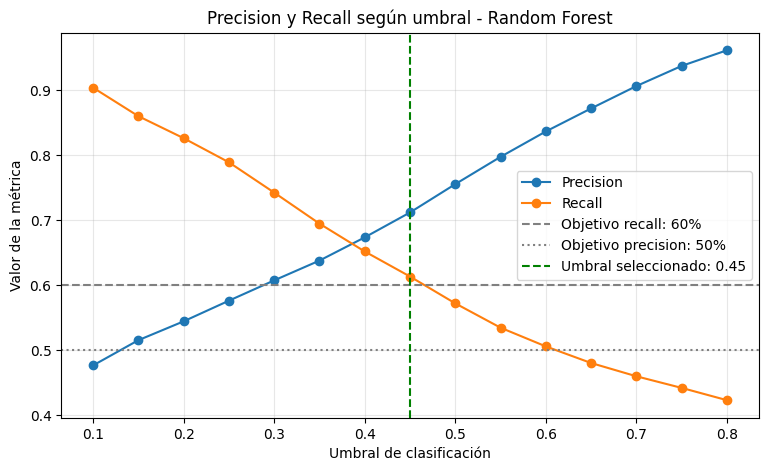

In [54]:
#Optimización umbral de decisión

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Probabilidades obtenidas mediante validación cruzada
probabilidades_cv = cross_val_predict(
    busqueda_rf.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    groups=grupos_train,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Evaluación de diferentes umbrales
umbrales = np.arange(0.10, 0.81, 0.05)
resultados_umbrales = []

for umbral in umbrales:
    predicciones = (probabilidades_cv >= umbral).astype(int)

    resultados_umbrales.append({
        'Umbral': round(float(umbral), 2),
        'Precision': precision_score(
            y_train, predicciones, zero_division=0
        ),
        'Recall': recall_score(
            y_train, predicciones, zero_division=0
        ),
        'F1': f1_score(
            y_train, predicciones, zero_division=0
        )
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

display(tabla_umbrales.round(4))

# Elegir el umbral con mayor precisión
# entre los que cumplen recall >= 60%
candidatos = tabla_umbrales[
    tabla_umbrales['Recall'] >= 0.60
]

if not candidatos.empty:
    mejor = candidatos.sort_values(
        ['Precision', 'Recall'],
        ascending=False
    ).iloc[0]

    umbral_optimo = float(mejor['Umbral'])

    print("\nUmbral seleccionado:", umbral_optimo)
    print("Precision CV:", round(mejor['Precision'], 4))
    print("Recall CV:", round(mejor['Recall'], 4))
else:
    umbral_optimo = None
    print("\nNingún umbral evaluado alcanza el recall objetivo.")

# Visualización
plt.figure(figsize=(9, 5))

plt.plot(
    tabla_umbrales['Umbral'],
    tabla_umbrales['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    tabla_umbrales['Umbral'],
    tabla_umbrales['Recall'],
    marker='o',
    label='Recall'
)

plt.axhline(
    y=0.60,
    linestyle='--',
    color='gray',
    label='Objetivo recall: 60%'
)

plt.axhline(
    y=0.50,
    linestyle=':',
    color='gray',
    label='Objetivo precision: 50%'
)

if umbral_optimo is not None:
    plt.axvline(
        x=umbral_optimo,
        linestyle='--',
        color='green',
        label=f'Umbral seleccionado: {umbral_optimo:.2f}'
    )

plt.xlabel('Umbral de clasificación')
plt.ylabel('Valor de la métrica')
plt.title('Precision y Recall según umbral - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [55]:
#Oprimización de regresión logística

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Pipeline de regresión logística
pipeline_logistico = Pipeline([
    ('preprocesamiento', clone(preprocesador)),
    ('clasificador', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Hiperparámetros a evaluar
parametros_logisticos = {
    'clasificador__C': [0.01, 0.1, 1, 10],
    'clasificador__class_weight': [None, 'balanced']
}

# Búsqueda mediante validación cruzada agrupada
busqueda_logistica = GridSearchCV(
    estimator=pipeline_logistico,
    param_grid=parametros_logisticos,
    scoring='recall',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

busqueda_logistica.fit(
    X_train,
    y_train,
    groups=grupos_train
)

print("Mejores hiperparámetros:")
print(busqueda_logistica.best_params_)

print("\nMejor recall promedio en validación cruzada:")
print(round(busqueda_logistica.best_score_, 4))

modelo_logistico_optimizado = busqueda_logistica.best_estimator_


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores hiperparámetros:
{'clasificador__C': 1, 'clasificador__class_weight': 'balanced'}

Mejor recall promedio en validación cruzada:
0.6142


,Umbral,Precision,Recall,F1
0,0.10,0.3798,0.9975,0.5502
1,0.15,0.3851,0.9912,0.5547
2,0.20,0.4089,0.9583,0.5732
3,0.25,0.4449,0.9176,0.5993
4,0.30,0.4750,0.8783,0.6165
5,0.35,0.5090,0.8493,0.6365
6,0.40,0.5423,0.8136,0.6508
7,0.45,0.6130,0.7371,0.6693
8,0.50,0.7008,0.6143,0.6547
9,0.55,0.8029,0.5265,0.6360



Umbral seleccionado: 0.5
Precision CV: 0.7008
Recall CV: 0.6143


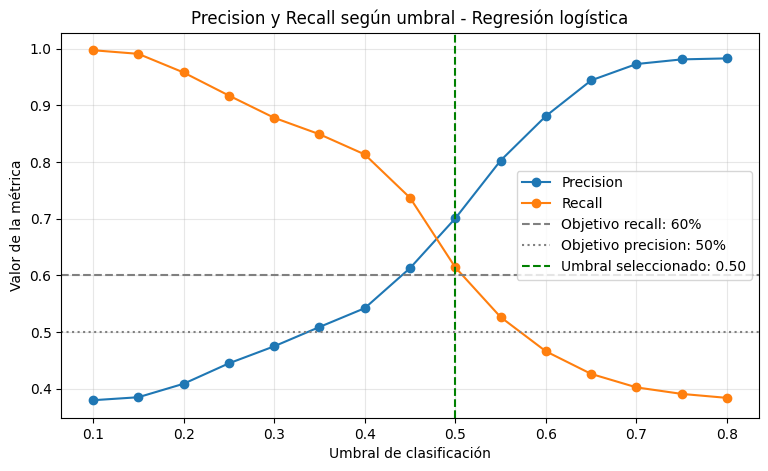

In [56]:
#Evaluación umbrales regresión logística

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predicciones mediante validación cruzada agrupada
probabilidades_log_cv = cross_val_predict(
    busqueda_logistica.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    groups=grupos_train,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Evaluar diferentes umbrales
umbrales = np.arange(0.10, 0.81, 0.05)
resultados_log_umbrales = []

for umbral in umbrales:
    predicciones = (
        probabilidades_log_cv >= umbral
    ).astype(int)

    resultados_log_umbrales.append({
        'Umbral': round(float(umbral), 2),
        'Precision': precision_score(
            y_train, predicciones, zero_division=0
        ),
        'Recall': recall_score(
            y_train, predicciones, zero_division=0
        ),
        'F1': f1_score(
            y_train, predicciones, zero_division=0
        )
    })

tabla_log_umbrales = pd.DataFrame(resultados_log_umbrales)

display(tabla_log_umbrales.round(4))

# Seleccionar el umbral con mayor precisión
# que alcance recall >= 60%
candidatos_log = tabla_log_umbrales[
    tabla_log_umbrales['Recall'] >= 0.60
]

if not candidatos_log.empty:
    mejor_log = candidatos_log.sort_values(
        ['Precision', 'Recall'],
        ascending=False
    ).iloc[0]

    umbral_log_optimo = float(mejor_log['Umbral'])

    print("\nUmbral seleccionado:", umbral_log_optimo)
    print("Precision CV:", round(mejor_log['Precision'], 4))
    print("Recall CV:", round(mejor_log['Recall'], 4))
else:
    umbral_log_optimo = None
    print("\nNingún umbral alcanza el recall objetivo.")

# Gráfico de precision y recall
plt.figure(figsize=(9, 5))

plt.plot(
    tabla_log_umbrales['Umbral'],
    tabla_log_umbrales['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    tabla_log_umbrales['Umbral'],
    tabla_log_umbrales['Recall'],
    marker='o',
    label='Recall'
)

plt.axhline(
    0.60,
    linestyle='--',
    color='gray',
    label='Objetivo recall: 60%'
)

plt.axhline(
    0.50,
    linestyle=':',
    color='gray',
    label='Objetivo precision: 50%'
)

if umbral_log_optimo is not None:
    plt.axvline(
        umbral_log_optimo,
        linestyle='--',
        color='green',
        label=f'Umbral seleccionado: {umbral_log_optimo:.2f}'
    )

plt.xlabel('Umbral de clasificación')
plt.ylabel('Valor de la métrica')
plt.title('Precision y Recall según umbral - Regresión logística')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


##Evaluación final de modelos optimizados

In [57]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

modelos_finales = {
    'Random Forest optimizado': (
        modelo_rf_optimizado, umbral_optimo
    ),
    'Regresión logística optimizada': (
        modelo_logistico_optimizado, umbral_log_optimo
    )
}

resultados_finales = []
matrices_finales = {}

for nombre, (modelo, umbral) in modelos_finales.items():

    probabilidades = modelo.predict_proba(X_test)[:, 1]
    predicciones = (probabilidades >= umbral).astype(int)

    resultados_finales.append({
        'Modelo': nombre,
        'Umbral': umbral,
        'Accuracy': accuracy_score(y_test, predicciones),
        'Precision': precision_score(
            y_test, predicciones, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predicciones, zero_division=0
        ),
        'F1': f1_score(
            y_test, predicciones, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, probabilidades)
    })

    matrices_finales[nombre] = confusion_matrix(
        y_test, predicciones
    )

comparacion_final = pd.DataFrame(resultados_finales)

print("COMPARACIÓN FINAL DE MODELOS")
display(comparacion_final.round(4))

print("\nMATRICES DE CONFUSIÓN")

for nombre, matriz in matrices_finales.items():
    print(f"\n{nombre}")
    print(matriz)

print("\nCUMPLIMIENTO DE OBJETIVOS")

for _, fila in comparacion_final.iterrows():
    cumple = (
        fila['Recall'] >= 0.60
        and fila['Precision'] >= 0.50
    )

    print(
        fila['Modelo'],
        "-",
        "Cumple ambos objetivos" if cumple
        else "No cumple ambos objetivos"
    )


COMPARACIÓN FINAL DE MODELOS


,Modelo,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest optimizado,0.45,0.7771,0.7291,0.6252,0.6732,0.8351
1,Regresión logística optimizada,0.50,0.7646,0.7049,0.6174,0.6583,0.8132



MATRICES DE CONFUSIÓN

Random Forest optimizado
[[11874  1850]
 [ 2984  4978]]

Regresión logística optimizada
[[11666  2058]
 [ 3046  4916]]

CUMPLIMIENTO DE OBJETIVOS
Random Forest optimizado - Cumple ambos objetivos
Regresión logística optimizada - Cumple ambos objetivos


# DESPLIEGUE DEL MODELO

## Peristencia del modelo y control de versión


In [58]:

import joblib
from pathlib import Path
from datetime import datetime, timezone

# Carpeta para los archivos del modelo
carpeta_modelo = Path("modelo")
carpeta_modelo.mkdir(exist_ok=True)

# Versión del modelo seleccionado
version_modelo = "1.0.0"
umbral_final = 0.45

# Guardar pipeline completo y configuración
artefacto_modelo = {
    "modelo": modelo_rf_optimizado,
    "version": version_modelo,
    "umbral": umbral_final,
    "variables": variables,
    "fecha_guardado": datetime.now(
        timezone.utc
    ).isoformat()
}

ruta_modelo = carpeta_modelo / "hotel_cancelaciones_v1.joblib"

joblib.dump(artefacto_modelo, ruta_modelo)

# Verificar que el archivo pueda recuperarse
modelo_cargado = joblib.load(ruta_modelo)

print("Modelo guardado correctamente:", ruta_modelo)
print("Versión:", modelo_cargado["version"])
print("Umbral:", modelo_cargado["umbral"])
print("Variables:", len(modelo_cargado["variables"]))


Modelo guardado correctamente: modelo/hotel_cancelaciones_v1.joblib
Versión: 1.0.0
Umbral: 0.45
Variables: 9


## Predicción por lotes y registro de bitácora

In [59]:

import joblib
import pandas as pd
import json
import time
from datetime import datetime, timezone
from pathlib import Path

# Cargar modelo persistido
artefacto = joblib.load(
    "modelo/hotel_cancelaciones_v1.joblib"
)

modelo = artefacto["modelo"]
version = artefacto["version"]
umbral = artefacto["umbral"]
columnas = artefacto["variables"]

# Preparar archivo de entrada de ejemplo
carpeta_datos = Path("datos")
carpeta_datos.mkdir(exist_ok=True)

ruta_entrada = carpeta_datos / "reservas_nuevas.csv"

X_test[columnas].head(5).to_csv(
    ruta_entrada, index=False
)

# Leer casos nuevos desde CSV
reservas = pd.read_csv(ruta_entrada)

# Verificar columnas requeridas
faltantes = set(columnas) - set(reservas.columns)

if faltantes:
    raise ValueError(
        f"Faltan columnas: {sorted(faltantes)}"
    )

reservas = reservas[columnas]

# Crear carpeta de resultados
carpeta_resultados = Path("resultados")
carpeta_resultados.mkdir(exist_ok=True)

resultados = []
registros = []

# Procesar cada reserva
for indice, (_, reserva) in enumerate(
    reservas.iterrows(), start=1
):
    inicio = time.perf_counter()

    entrada = reserva.to_frame().T
    entrada = entrada.infer_objects()

    probabilidad = float(
        modelo.predict_proba(entrada)[0, 1]
    )

    prediccion = int(probabilidad >= umbral)

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    fecha_hora = datetime.now(
        timezone.utc
    ).isoformat()

    resultados.append({
        "id_caso": indice,
        "probabilidad_cancelacion": probabilidad,
        "prediccion_cancelacion": prediccion,
        "version_modelo": version
    })

    registros.append({
        "fecha_hora": fecha_hora,
        "version_modelo": version,
        "id_caso": indice,
        "resumen_entrada": json.dumps(
            reserva.to_dict(),
            ensure_ascii=False,
            default=str
        ),
        "prediccion": prediccion,
        "tiempo_ejecucion_ms": round(tiempo_ms, 3)
    })

# Guardar predicciones
df_resultados = pd.DataFrame(resultados)

df_resultados.to_csv(
    carpeta_resultados / "predicciones.csv",
    index=False
)

# Guardar bitácora
df_bitacora = pd.DataFrame(registros)

df_bitacora.to_csv(
    carpeta_resultados / "bitacora.csv",
    index=False
)

print("Predicciones generadas correctamente.")
print("\nRESULTADOS:")
display(df_resultados.round(4))

print("\nBITÁCORA:")
display(df_bitacora[
    [
        "fecha_hora",
        "version_modelo",
        "id_caso",
        "prediccion",
        "tiempo_ejecucion_ms"
    ]
])


Predicciones generadas correctamente.

RESULTADOS:


,id_caso,probabilidad_cancelacion,prediccion_cancelacion,version_modelo
0,1,0.2433,0,1.0.0
1,2,0.5688,1,1.0.0
2,3,0.1674,0,1.0.0
3,4,0.0444,0,1.0.0
4,5,0.0295,0,1.0.0



BITÁCORA:


,fecha_hora,version_modelo,id_caso,prediccion,tiempo_ejecucion_ms
0,2026-11-14T15:18:12.593074+00:00,1.0.0,1,0,39.259
1,2026-11-14T15:18:12.658496+00:00,1.0.0,2,1,65.060
2,2026-11-14T15:18:12.744980+00:00,1.0.0,3,0,85.918
3,2026-11-14T15:18:12.859221+00:00,1.0.0,4,0,113.807
4,2026-11-14T15:18:12.977876+00:00,1.0.0,5,0,118.262


## Generación del script de predicción por lotes

In [60]:

%%writefile predecir_lotes.py
import argparse
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import pandas as pd


def ejecutar_predicciones(ruta_entrada, ruta_modelo, carpeta_salida):
    artefacto = joblib.load(ruta_modelo)
    modelo = artefacto["modelo"]
    version = artefacto["version"]
    umbral = artefacto["umbral"]
    columnas = artefacto["variables"]

    reservas = pd.read_csv(ruta_entrada)

    faltantes = set(columnas) - set(reservas.columns)
    if faltantes:
        raise ValueError(f"Faltan columnas: {sorted(faltantes)}")

    reservas = reservas[columnas]

    salida = Path(carpeta_salida)
    salida.mkdir(parents=True, exist_ok=True)

    resultados = []
    registros = []

    for numero, (_, reserva) in enumerate(reservas.iterrows(), start=1):
        inicio = time.perf_counter()

        entrada = reserva.to_frame().T.infer_objects()
        probabilidad = float(modelo.predict_proba(entrada)[0, 1])
        prediccion = int(probabilidad >= umbral)

        tiempo_ms = (time.perf_counter() - inicio) * 1000

        resultados.append({
            "id_caso": numero,
            "probabilidad_cancelacion": probabilidad,
            "prediccion_cancelacion": prediccion,
            "version_modelo": version
        })

        registros.append({
            "fecha_hora": datetime.now(timezone.utc).isoformat(),
            "version_modelo": version,
            "id_caso": numero,
            "resumen_entrada": json.dumps(
                reserva.to_dict(),
                ensure_ascii=False,
                default=str
            ),
            "prediccion": prediccion,
            "tiempo_ejecucion_ms": round(tiempo_ms, 3)
        })

    pd.DataFrame(resultados).to_csv(
        salida / "predicciones.csv", index=False
    )

    pd.DataFrame(registros).to_csv(
        salida / "bitacora.csv", index=False
    )

    print(f"Reservas procesadas: {len(reservas)}")
    print(f"Predicciones guardadas en: {salida / 'predicciones.csv'}")
    print(f"Bitácora guardada en: {salida / 'bitacora.csv'}")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="Predicción de cancelaciones hoteleras por lotes"
    )
    parser.add_argument("--entrada", required=True)
    parser.add_argument(
        "--modelo",
        default="modelo/hotel_cancelaciones_v1.joblib"
    )
    parser.add_argument("--salida", default="resultados")

    args = parser.parse_args()

    ejecutar_predicciones(args.entrada, args.modelo, args.salida)


Writing predecir_lotes.py


In [61]:
# Prueba del Script independiente
!python predecir_lotes.py --entrada datos/reservas_nuevas.csv --modelo modelo/hotel_cancelaciones_v1.joblib --salida resultados/prueba_script


Reservas procesadas: 5
Predicciones guardadas en: resultados/prueba_script/predicciones.csv
Bitácora guardada en: resultados/prueba_script/bitacora.csv


# MONITOREO

## Monitoreo del desempeño en producción simulada

In [62]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Recuperar modelo y umbral definitivos
modelo_final = modelo_rf_optimizado
umbral_final = 0.45

# Predicciones sobre datos reservados para producción
probabilidades_prod = modelo_final.predict_proba(
    X_produccion
)[:, 1]

predicciones_prod = (
    probabilidades_prod >= umbral_final
).astype(int)

# Métricas de producción simulada
metricas_produccion = {
    'Accuracy': accuracy_score(
        y_produccion, predicciones_prod
    ),
    'Precision': precision_score(
        y_produccion, predicciones_prod, zero_division=0
    ),
    'Recall': recall_score(
        y_produccion, predicciones_prod, zero_division=0
    ),
    'F1': f1_score(
        y_produccion, predicciones_prod, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(
        y_produccion, probabilidades_prod
    )
}

# Comparación con las métricas de evaluación
metricas_offline = comparacion_final.loc[
    comparacion_final['Modelo'] == 'Random Forest optimizado'
].iloc[0]

comparacion_monitoreo = pd.DataFrame({
    'Metrica': list(metricas_produccion.keys()),
    'Evaluacion_offline': [
        metricas_offline[metrica]
        for metrica in metricas_produccion
    ],
    'Produccion_simulada': list(
        metricas_produccion.values()
    )
})

comparacion_monitoreo['Diferencia'] = (
    comparacion_monitoreo['Produccion_simulada']
    - comparacion_monitoreo['Evaluacion_offline']
)

print("COMPARACIÓN DE DESEMPEÑO")
display(comparacion_monitoreo.round(4))

print("\nMATRIZ DE CONFUSIÓN EN PRODUCCIÓN")
print(confusion_matrix(
    y_produccion, predicciones_prod
))

print("\nCUMPLIMIENTO DE OBJETIVOS EN PRODUCCIÓN")

cumple = (
    metricas_produccion['Recall'] >= 0.60
    and metricas_produccion['Precision'] >= 0.50
)

print(
    "Cumple ambos objetivos"
    if cumple else "No cumple ambos objetivos"
)


COMPARACIÓN DE DESEMPEÑO


,Metrica,Evaluacion_offline,Produccion_simulada,Diferencia
0,Accuracy,0.7771,0.6509,-0.1262
1,Precision,0.7291,0.5363,-0.1928
2,Recall,0.6252,0.4395,-0.1857
3,F1,0.6732,0.4831,-0.1901
4,ROC-AUC,0.8351,0.6815,-0.1536



MATRIZ DE CONFUSIÓN EN PRODUCCIÓN
[[4994 1444]
 [2130 1670]]

CUMPLIMIENTO DE OBJETIVOS EN PRODUCCIÓN
No cumple ambos objetivos


In [63]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Recuperar modelo y umbral definitivos
modelo_final = modelo_rf_optimizado
umbral_final = 0.45

# Predicciones sobre datos reservados para producción
probabilidades_prod = modelo_final.predict_proba(
    X_produccion
)[:, 1]

predicciones_prod = (
    probabilidades_prod >= umbral_final
).astype(int)

# Métricas de producción simulada
metricas_produccion = {
    'Accuracy': accuracy_score(
        y_produccion, predicciones_prod
    ),
    'Precision': precision_score(
        y_produccion, predicciones_prod, zero_division=0
    ),
    'Recall': recall_score(
        y_produccion, predicciones_prod, zero_division=0
    ),
    'F1': f1_score(
        y_produccion, predicciones_prod, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(
        y_produccion, probabilidades_prod
    )
}

# Comparación con las métricas de evaluación
metricas_offline = comparacion_final.loc[
    comparacion_final['Modelo'] == 'Random Forest optimizado'
].iloc[0]

comparacion_monitoreo = pd.DataFrame({
    'Metrica': list(metricas_produccion.keys()),
    'Evaluacion_offline': [
        metricas_offline[metrica]
        for metrica in metricas_produccion
    ],
    'Produccion_simulada': list(
        metricas_produccion.values()
    )
})

comparacion_monitoreo['Diferencia'] = (
    comparacion_monitoreo['Produccion_simulada']
    - comparacion_monitoreo['Evaluacion_offline']
)

print("COMPARACIÓN DE DESEMPEÑO")
display(comparacion_monitoreo.round(4))

print("\nMATRIZ DE CONFUSIÓN EN PRODUCCIÓN")
print(confusion_matrix(
    y_produccion, predicciones_prod
))

print("\nCUMPLIMIENTO DE OBJETIVOS EN PRODUCCIÓN")

cumple = (
    metricas_produccion['Recall'] >= 0.60
    and metricas_produccion['Precision'] >= 0.50
)

print(
    "Cumple ambos objetivos"
    if cumple else "No cumple ambos objetivos"
)


COMPARACIÓN DE DESEMPEÑO


,Metrica,Evaluacion_offline,Produccion_simulada,Diferencia
0,Accuracy,0.7771,0.6509,-0.1262
1,Precision,0.7291,0.5363,-0.1928
2,Recall,0.6252,0.4395,-0.1857
3,F1,0.6732,0.4831,-0.1901
4,ROC-AUC,0.8351,0.6815,-0.1536



MATRIZ DE CONFUSIÓN EN PRODUCCIÓN
[[4994 1444]
 [2130 1670]]

CUMPLIMIENTO DE OBJETIVOS EN PRODUCCIÓN
No cumple ambos objetivos


##Intervalor de confianza y detección de cambios en las variables

In [64]:

import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

# Intervalo de confianza del recall en producción
verdaderos_positivos = int(
    ((y_produccion.to_numpy() == 1) &
     (predicciones_prod == 1)).sum()
)

total_cancelaciones = int(
    (y_produccion.to_numpy() == 1).sum()
)

ic_inferior, ic_superior = proportion_confint(
    count=verdaderos_positivos,
    nobs=total_cancelaciones,
    alpha=0.05,
    method='wilson'
)

print("INTERVALO DE CONFIANZA DEL RECALL")
print(f"Recall: {metricas_produccion['Recall']:.4f}")
print(f"IC 95%: [{ic_inferior:.4f}, {ic_superior:.4f}]")


# PSI para variables numéricas
def calcular_psi(referencia, actual, bins=10):
    referencia = pd.Series(referencia).dropna()
    actual = pd.Series(actual).dropna()

    cortes = np.unique(
        np.quantile(
            referencia,
            np.linspace(0, 1, bins + 1)
        )
    )

    if len(cortes) < 3:
        return np.nan

    cortes[0] = -np.inf
    cortes[-1] = np.inf

    dist_ref = pd.cut(
        referencia, bins=cortes, include_lowest=True
    ).value_counts(normalize=True, sort=False)

    dist_actual = pd.cut(
        actual, bins=cortes, include_lowest=True
    ).value_counts(normalize=True, sort=False)

    esperado = np.clip(dist_ref.to_numpy(), 1e-6, None)
    observado = np.clip(dist_actual.to_numpy(), 1e-6, None)

    return np.sum(
        (observado - esperado) *
        np.log(observado / esperado)
    )


resultados_psi = []

for variable in variables_numericas:
    psi = calcular_psi(
        X_train[variable],
        X_produccion[variable]
    )

    resultados_psi.append({
        'Variable': variable,
        'PSI': psi,
        'Interpretacion': (
            'No calculable' if np.isnan(psi)
            else 'Cambio importante' if psi >= 0.25
            else 'Cambio moderado' if psi >= 0.10
            else 'Cambio bajo'
        )
    })

tabla_psi = pd.DataFrame(resultados_psi)

print("\nCAMBIOS DE DISTRIBUCIÓN (PSI)")
display(tabla_psi.round(4))


INTERVALO DE CONFIANZA DEL RECALL
Recall: 0.4395
IC 95%: [0.4238, 0.4553]

CAMBIOS DE DISTRIBUCIÓN (PSI)


,Variable,PSI,Interpretacion
0,lead_time,0.2452,Cambio moderado
1,previous_cancellations,NaN,No calculable
2,stays_in_week_nights,0.0826,Cambio bajo
3,stays_in_weekend_nights,0.0441,Cambio bajo


## Monitoreo de variables categóricas y alertas de reentrenamiento

In [65]:

import numpy as np
import pandas as pd

# PSI para variables categóricas o discretas
def calcular_psi_categorico(referencia, actual):
    ref = pd.Series(referencia).fillna("__FALTANTE__").astype(str)
    act = pd.Series(actual).fillna("__FALTANTE__").astype(str)

    categorias = sorted(set(ref.unique()) | set(act.unique()))

    p_ref = ref.value_counts(normalize=True).reindex(
        categorias, fill_value=0
    )
    p_act = act.value_counts(normalize=True).reindex(
        categorias, fill_value=0
    )

    # Suavizado para evitar logaritmos de cero
    epsilon = 1e-6
    p_ref = np.maximum(p_ref.to_numpy(), epsilon)
    p_act = np.maximum(p_act.to_numpy(), epsilon)

    return float(np.sum(
        (p_act - p_ref) * np.log(p_act / p_ref)
    ))


variables_discretas = (
    variables_categoricas + ["previous_cancellations"]
)

resultados_psi_adicionales = []

for variable in variables_discretas:
    psi = calcular_psi_categorico(
        X_train[variable],
        X_produccion[variable]
    )

    resultados_psi_adicionales.append({
        "Variable": variable,
        "PSI": psi,
        "Interpretacion": (
            "Cambio importante" if psi >= 0.25
            else "Cambio moderado" if psi >= 0.10
            else "Cambio bajo"
        )
    })

tabla_psi_adicional = pd.DataFrame(
    resultados_psi_adicionales
)

# Unificar el monitoreo de las nueve variables
tabla_psi_completa = pd.concat([
    tabla_psi[
        tabla_psi["Variable"] != "previous_cancellations"
    ],
    tabla_psi_adicional
], ignore_index=True)

print("PSI DE LAS NUEVE VARIABLES")
display(
    tabla_psi_completa.sort_values(
        "PSI", ascending=False
    ).round(4)
)

# Regla propuesta para activar revisión y reentrenamiento
alerta_desempeno = (
    metricas_produccion["Recall"] < 0.60
    or metricas_produccion["Precision"] < 0.50
)

alerta_distribucion = (
    tabla_psi_completa["PSI"] >= 0.25
).any()

print("\nALERTAS DE MONITOREO")
print("Alerta por desempeño:", alerta_desempeno)
print("Alerta por distribución:", alerta_distribucion)

if alerta_desempeno or alerta_distribucion:
    print(
        "ACCIÓN: revisar el modelo y evaluar "
        "su reentrenamiento con datos recientes."
    )
else:
    print("ACCIÓN: continuar monitoreo periódico.")


PSI DE LAS NUEVE VARIABLES


,Variable,PSI,Interpretacion
5,market_segment,0.3461,Cambio importante
0,lead_time,0.2452,Cambio moderado
4,deposit_type,0.2018,Cambio moderado
8,previous_cancellations,0.1504,Cambio moderado
1,stays_in_week_nights,0.0826,Cambio bajo
6,customer_type,0.0809,Cambio bajo
2,stays_in_weekend_nights,0.0441,Cambio bajo
7,is_repeated_guest,0.0055,Cambio bajo
3,hotel,0.0009,Cambio bajo



ALERTAS DE MONITOREO
Alerta por desempeño: True
Alerta por distribución: True
ACCIÓN: revisar el modelo y evaluar su reentrenamiento con datos recientes.


# INTERPRETACIÓN DEL MODELO

## Interpretabilidad del modelo y análisis de predicciones individuales

IMPORTANCIA DE VARIABLES


,Variable,Importancia
5,deposit_type,0.1898
6,market_segment,0.0668
0,lead_time,0.0588
7,customer_type,0.0482
1,previous_cancellations,0.0326
2,stays_in_week_nights,0.0195
3,stays_in_weekend_nights,0.0137
4,hotel,0.0130
8,is_repeated_guest,0.0069


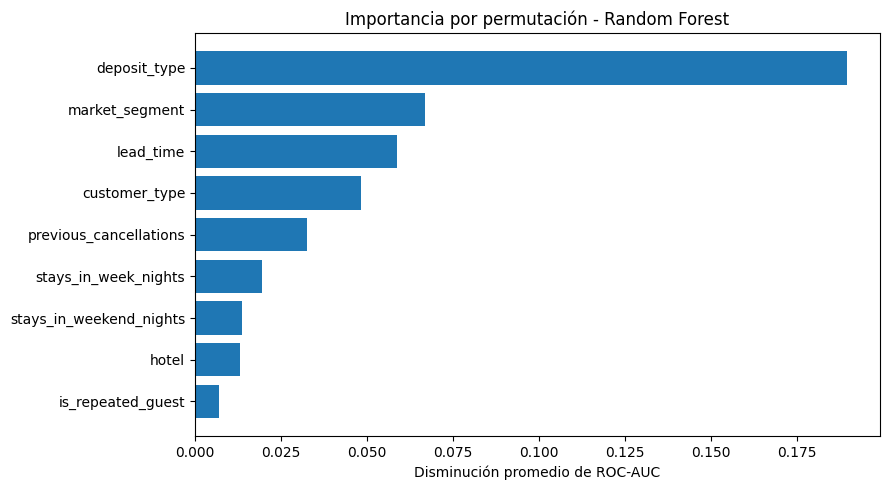


TRES PREDICCIONES INDIVIDUALES

Cancelación correctamente detectada


,lead_time,previous_cancellations,stays_in_week_nights,stays_in_weekend_nights,hotel,deposit_type,market_segment,customer_type,is_repeated_guest,Probabilidad_cancelacion,Prediccion,Resultado_real
10,23,0,4,0,Resort Hotel,No Deposit,Online TA,Transient,0,0.5688,1,1



Falsa alerta de cancelación


,lead_time,previous_cancellations,stays_in_week_nights,stays_in_weekend_nights,hotel,deposit_type,market_segment,customer_type,is_repeated_guest,Probabilidad_cancelacion,Prediccion,Resultado_real
73,15,0,2,0,Resort Hotel,No Deposit,Online TA,Transient,0,0.5288,1,0



Cancelación no detectada


,lead_time,previous_cancellations,stays_in_week_nights,stays_in_weekend_nights,hotel,deposit_type,market_segment,customer_type,is_repeated_guest,Probabilidad_cancelacion,Prediccion,Resultado_real
32,96,0,8,2,Resort Hotel,No Deposit,Direct,Transient,0,0.3,0,1


In [66]:

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Utilizar el modelo definitivo ya entrenado
modelo_interpretacion = modelo_rf_optimizado
umbral_interpretacion = 0.45

# Muestra de evaluación para reducir tiempo de ejecución
X_muestra = X_test.sample(n=2000, random_state=42)
y_muestra = y_test.loc[X_muestra.index]

# Importancia por permutación
importancias = permutation_importance(
    modelo_interpretacion,
    X_muestra,
    y_muestra,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

tabla_importancias = pd.DataFrame({
    "Variable": X_muestra.columns,
    "Importancia": importancias.importances_mean
}).sort_values("Importancia", ascending=False)

print("IMPORTANCIA DE VARIABLES")
display(tabla_importancias.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    tabla_importancias["Variable"][::-1],
    tabla_importancias["Importancia"][::-1]
)
plt.xlabel("Disminución promedio de ROC-AUC")
plt.title("Importancia por permutación - Random Forest")
plt.tight_layout()
plt.show()

# Obtener probabilidades del conjunto de evaluación
probabilidades = modelo_interpretacion.predict_proba(
    X_test
)[:, 1]

predicciones = (
    probabilidades >= umbral_interpretacion
).astype(int)

casos = pd.DataFrame({
    "Probabilidad_cancelacion": probabilidades,
    "Prediccion": predicciones,
    "Resultado_real": y_test.to_numpy()
}, index=X_test.index)

# Seleccionar tres tipos de resultados
tipos_casos = [
    ("Cancelación correctamente detectada", 1, 1),
    ("Falsa alerta de cancelación", 1, 0),
    ("Cancelación no detectada", 0, 1)
]

seleccionados = []

for descripcion, pred, real in tipos_casos:
    candidatos = casos[
        (casos["Prediccion"] == pred) &
        (casos["Resultado_real"] == real)
    ]

    if not candidatos.empty:
        indice = candidatos.index[0]
        seleccionados.append((descripcion, indice))

print("\nTRES PREDICCIONES INDIVIDUALES")

for descripcion, indice in seleccionados:
    print(f"\n{descripcion}")
    display(
        pd.concat([
            X_test.loc[[indice]],
            casos.loc[[indice]]
        ], axis=1).round(4)
    )


# DOCUMENTACION, REPRODUCIBILIDAD Y ENTREGA

## Documentación del proyecto – README

In [67]:

from pathlib import Path

readme = """# Predicción de cancelaciones hoteleras

## Objetivo
Desarrollar un modelo de aprendizaje automático para predecir
la cancelación de reservas hoteleras y apoyar la gestión comercial.

## Datos
Dataset: Hotel Booking Demand.
Variable objetivo: is_canceled (1 = cancelación, 0 = no cancelación).

## Modelo seleccionado
Random Forest optimizado.
Versión: 1.0.0
Umbral de clasificación: 0.45

## Resultados de evaluación
- Precision: 72.91%
- Recall: 62.52%
- F1-score: 67.32%
- ROC-AUC: 83.51%

## Monitoreo de producción simulada
- Precision: 53.63%
- Recall: 43.95%
- ROC-AUC: 68.15%

El monitoreo detectó deterioro del rendimiento y cambios
en la distribución de algunas variables predictoras.

## Archivos principales
- Notebook de Colab: desarrollo, entrenamiento y evaluación.
- modelo/hotel_cancelaciones_v1.joblib: modelo entrenado.
- predecir_lotes.py: script de predicción por lotes.
- datos/reservas_nuevas.csv: ejemplo de entrada.
- resultados/: predicciones y bitácoras.

## Ejecución de predicciones
Ejecutar desde la carpeta principal del proyecto:

python predecir_lotes.py --entrada datos/reservas_nuevas.csv

El script genera:
- predicciones.csv
- bitacora.csv

## Variables requeridas
lead_time, previous_cancellations, stays_in_week_nights,
stays_in_weekend_nights, hotel, deposit_type, market_segment,
customer_type, is_repeated_guest.

## Dependencias
Instalar con:

pip install -r requirements.txt

## Limitaciones
El modelo requiere monitoreo y revisión antes de su utilización
en un entorno productivo real.
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("README.md creado correctamente")


README.md creado correctamente


## Dependencias del proyecto, requirements.txt

In [68]:

from pathlib import Path
import importlib.metadata as metadata

paquetes = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "joblib",
    "matplotlib",
    "statsmodels"
]

dependencias = "\n".join(
    f"{paquete}=={metadata.version(paquete)}"
    for paquete in paquetes
) + "\n"

Path("requirements.txt").write_text(
    dependencias,
    encoding="utf-8"
)

print("requirements.txt creado correctamente")
print(dependencias)


requirements.txt creado correctamente
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
joblib==1.6.0
matplotlib==3.10.0
statsmodels==0.15.0



## Verificación de entregable

In [69]:

from pathlib import Path

archivos = [
    "README.md",
    "requirements.txt",
    "predecir_lotes.py",
    "modelo/hotel_cancelaciones_v1.joblib",
    "datos/reservas_nuevas.csv",
    "resultados/prueba_script/predicciones.csv",
    "resultados/prueba_script/bitacora.csv"
]

for archivo in archivos:
    estado = "OK" if Path(archivo).is_file() else "FALTA"
    print(f"{estado}: {archivo}")


OK: README.md
OK: requirements.txt
OK: predecir_lotes.py
OK: modelo/hotel_cancelaciones_v1.joblib
OK: datos/reservas_nuevas.csv
OK: resultados/prueba_script/predicciones.csv
OK: resultados/prueba_script/bitacora.csv


## Preparación ZIP del proyecto

In [70]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

archivos_entrega = [
    "README.md",
    "requirements.txt",
    "predecir_lotes.py",
    "modelo/hotel_cancelaciones_v1.joblib",
    "datos/reservas_nuevas.csv",
    "resultados/prueba_script/predicciones.csv",
    "resultados/prueba_script/bitacora.csv"
]

nombre_zip = "proyecto_cancelaciones_hoteleras.zip"

with ZipFile(nombre_zip, "w", ZIP_DEFLATED) as zipf:
    for archivo in archivos_entrega:
        zipf.write(archivo)

print(f"Paquete creado: {nombre_zip}")
print("Archivos incluidos:")
for archivo in archivos_entrega:
    print("-", archivo)


Paquete creado: proyecto_cancelaciones_hoteleras.zip
Archivos incluidos:
- README.md
- requirements.txt
- predecir_lotes.py
- modelo/hotel_cancelaciones_v1.joblib
- datos/reservas_nuevas.csv
- resultados/prueba_script/predicciones.csv
- resultados/prueba_script/bitacora.csv
